
 TRANSIENT BATCH EVALUATION: 8 CIRCUITS (FOLDED CASCODE BUFFER)
Compiled Custom DC, AC, and Transient Simulator Successfully!
>>> Running 8-Batch Transient Solves on Julia Threads...
Julia 8-Circuit Transient Total Time: 1.877 s

>>> Running LTspice baseline (Sequential)...
LTspice Total Time: 4.678 s

 🚀 TRANSIENT PERFORMANCE SUMMARY
 JuliaGSim Time : 1.877 seconds
 LTspice Time   : 4.678 seconds
 Speedup Factor : 2.49x faster than LTspice!

 DETAILED CIRCUIT RESULTS (SR & WAVEFORMS)

------------------------------------------------------------
Circuit 1 - Params: M=20.0, L=1.0um, MB=10.0
------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 22.41       V/us | 20.91       V/us
Difference      | 1.50        V/us |



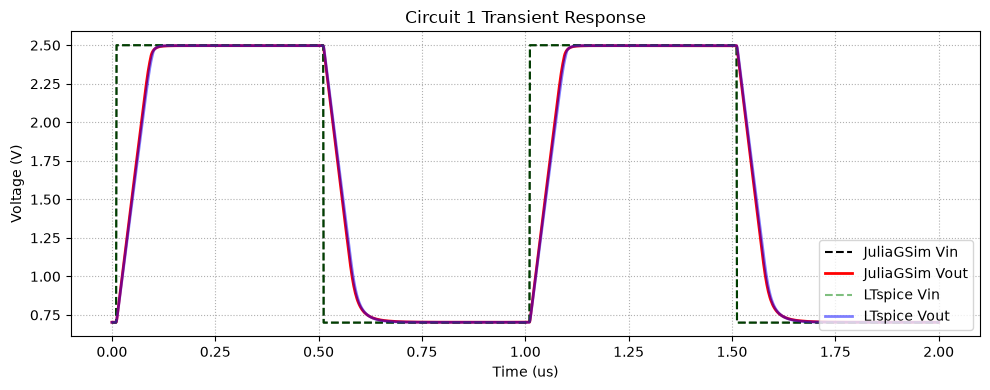


------------------------------------------------------------
Circuit 2 - Params: M=60.0, L=1.0um, MB=10.0
------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 18.32       V/us | 17.26       V/us
Difference      | 1.06        V/us |



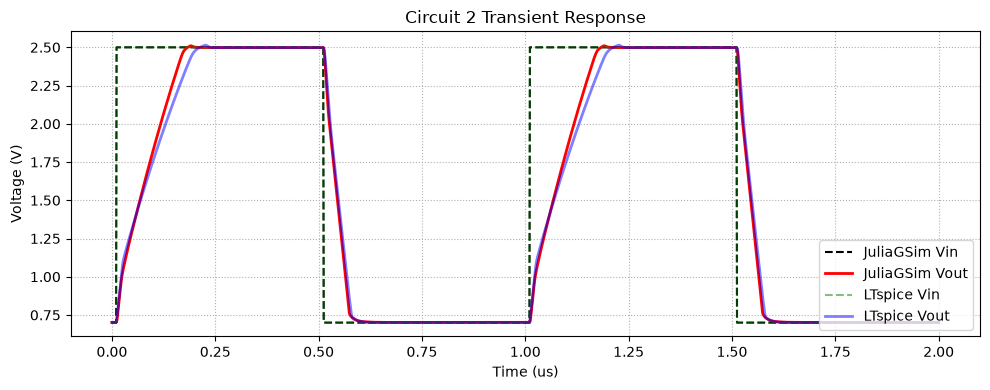


------------------------------------------------------------
Circuit 3 - Params: M=20.0, L=5.0um, MB=10.0
------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 20.13       V/us | 19.63       V/us
Difference      | 0.50        V/us |



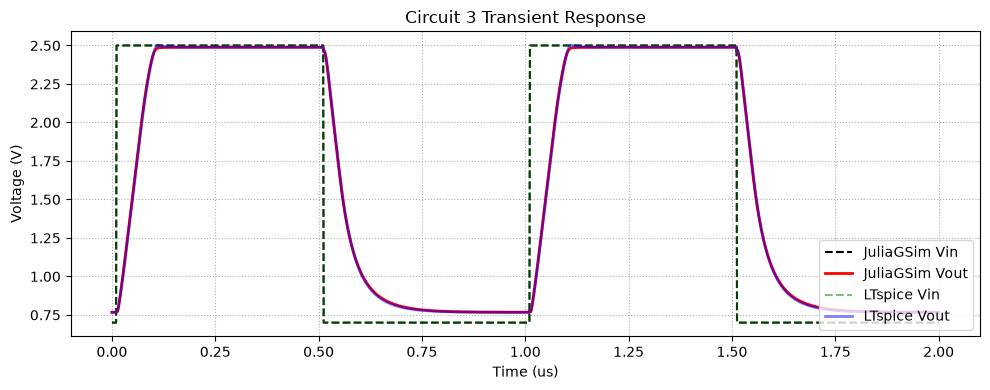


------------------------------------------------------------
Circuit 4 - Params: M=60.0, L=5.0um, MB=10.0
------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 14.29       V/us | 14.57       V/us
Difference      | 0.28        V/us |



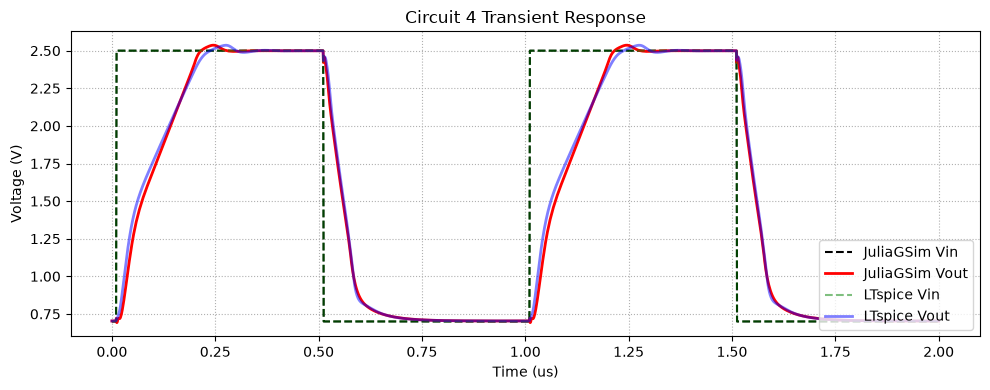


------------------------------------------------------------
Circuit 5 - Params: M=20.0, L=1.0um, MB=30.0
------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 9.84        V/us | 9.56        V/us
Difference      | 0.27        V/us |



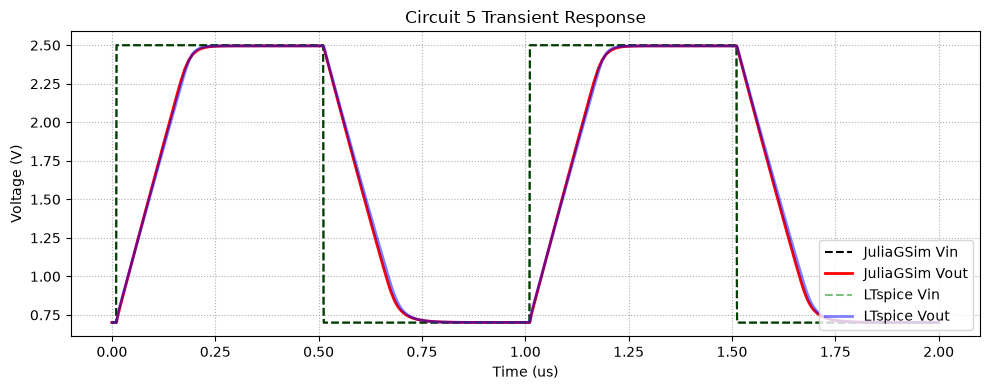


------------------------------------------------------------
Circuit 6 - Params: M=60.0, L=1.0um, MB=30.0
------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 22.42       V/us | 19.70       V/us
Difference      | 2.73        V/us |



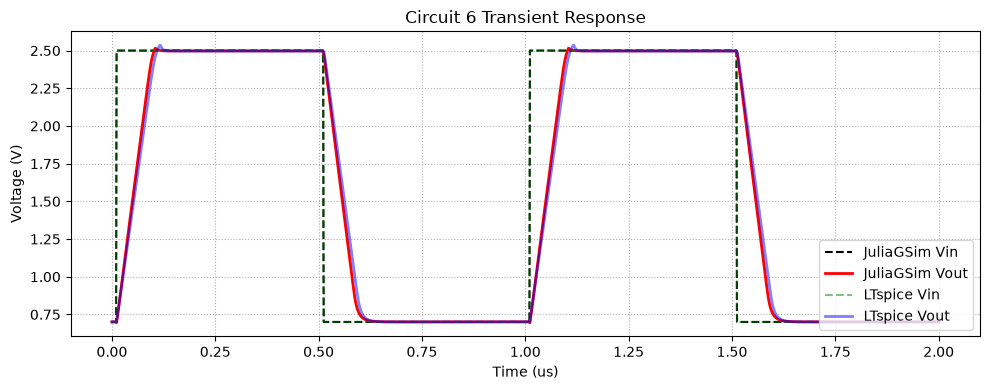


------------------------------------------------------------
Circuit 7 - Params: M=20.0, L=5.0um, MB=30.0
------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 9.36        V/us | 9.13        V/us
Difference      | 0.23        V/us |



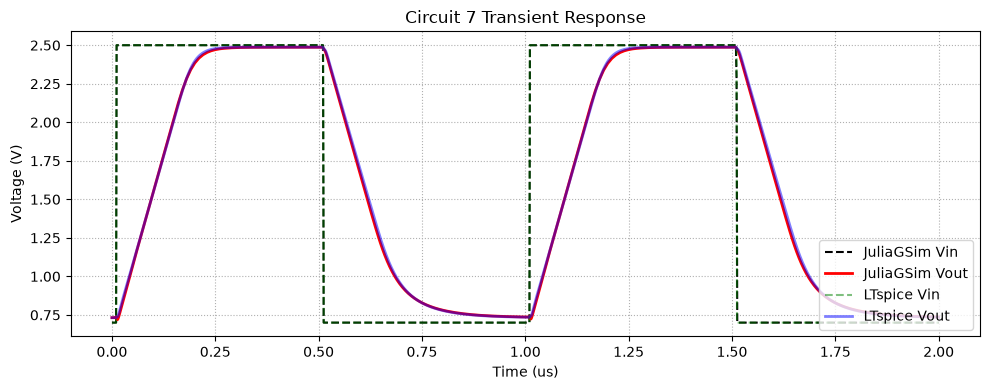


------------------------------------------------------------
Circuit 8 - Params: M=60.0, L=5.0um, MB=30.0
------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 19.95       V/us | 19.12       V/us
Difference      | 0.84        V/us |



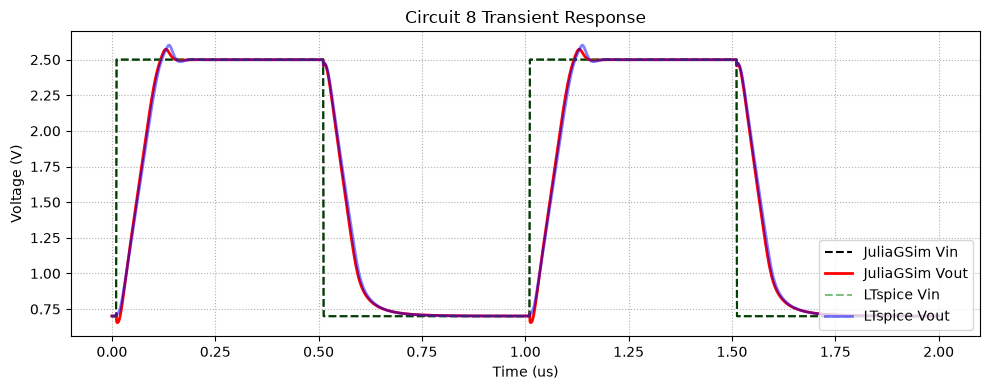

In [3]:
# 0. Set Python Environment
ENV["JULIA_PYTHONCALL_EXE"] = "C:\\Users\\mohamed\\.conda\\envs\\Thesis_Optimizer_Sandbox_Copy\\python.exe"

using Printf
using StaticArrays
using PythonCall
using Random

# ==============================================================================
# 1. Call the LUT definitions and the simulator Engine
# ==============================================================================
# 1. Load technology model definitions
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Surrogate_definitions.jl")

# 2. Load the Engine (choose Static for small circuits or Sparse for large circuits)
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Static_Sim.jl")

# ==============================================================================
# 2. LTSPICE VERIFICATION GROUND TRUTH 
# ==============================================================================
g = pydict()
pyexec(raw"""
import os, subprocess, numpy as np
from PyLTSpice import RawRead

def run_ltspice_fc_tran(md, Ld, mp_src, Lp, mss, Lss, mp_csc, mm_mir, mm_csc, Lm, mb, Ib, I_cascode, CL, BASE_DIR='.'):
    os.makedirs(BASE_DIR, exist_ok=True)
    LTSPICE_PATH = r"C:\Users\Mohamed\AppData\Local\Programs\ADI\LTspice\LTspice.exe"
    
    m_bias_p_csc = mp_csc / 4.0
    m_bias_n_csc = mm_csc / 4.0
    I_tail = Ib * (mss/mb)
    I_pmos = I_tail/2.0 + I_cascode
    
    netlist = f'''* NMOS-Input Folded Cascode OTA Slew Rate Buffer Testbench
Vdd Vdd 0 3
Vin vip 0 PULSE(0.7 2.5 10n 1n 1n 500n 1u)
IB Vdd vb {Ib}

I_Vbp Vbp 0 {I_pmos}
I_VcscP VcscP 0 {I_cascode}
I_VcscN Vdd VcscN {I_cascode}

M_bias vb vb 0 0 nmos_3p3 l={Lss} w=0.5u m={mb}
M_bias_p Vbp Vbp Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={mp_src}
M_bias_cscP VcscP VcscP Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={m_bias_p_csc}
M_bias_cscN VcscN VcscN 0 0 nmos_3p3 l={Lm} w=0.5u m={m_bias_n_csc}

M_tail vT vb 0 0 nmos_3p3 l={Lss} w=0.5u m={mss}
M1 vfold_p vip vT 0 nmos_3p3 l={Ld} w=0.5u m={md}
M2 vfold_n vout vT 0 nmos_3p3 l={Ld} w=0.5u m={md}

M3 vfold_p Vbp Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={mp_src}
M4 vfold_n Vbp Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={mp_src}

M5 vx_left VcscP vfold_p Vdd pmos_3p3 l={Lp} w=0.5u m={mp_csc}
M6 vout VcscP vfold_n Vdd pmos_3p3 l={Lp} w=0.5u m={mp_csc}

M7 vy_left vx_left 0 0 nmos_3p3 l={Lm} w=0.5u m={mm_mir}
M8 vout_bot vx_left 0 0 nmos_3p3 l={Lm} w=0.5u m={mm_mir}

M9 vx_left VcscN vy_left 0 nmos_3p3 l={Lm} w=0.5u m={mm_csc}
M10 vout VcscN vout_bot 0 nmos_3p3 l={Lm} w=0.5u m={mm_csc}

CL vout 0 {CL}

.model NMOS NMOS
.model PMOS PMOS
.inc cmos_tt.txt
.lib {os.path.join(os.environ.get('LOCALAPPDATA', ''), 'LTspice', 'lib', 'cmp', 'standard.mos')}

.options plotwinsize=0
.tran 0 2u 0 1n
* MEASUREMENTS
.meas TRAN v_high FIND V(vout) AT 490n
.meas TRAN v_low FIND V(vout) AT 990n
.meas TRAN v_20 PARAM v_low + 0.2*(v_high-v_low)
.meas TRAN v_80 PARAM v_low + 0.8*(v_high-v_low)
.meas TRAN t_r20 FIND time WHEN V(vout)=v_20 RISE=1
.meas TRAN t_r80 FIND time WHEN V(vout)=v_80 RISE=1
.meas TRAN sr_rise PARAM (v_80-v_20)/(t_r80-t_r20)
.meas TRAN t_f80 FIND time WHEN V(vout)=v_80 FALL=1
.meas TRAN t_f20 FIND time WHEN V(vout)=v_20 FALL=1
.meas TRAN sr_fall PARAM (v_80-v_20)/(t_f20-t_f80)
.meas TRAN sr_avg PARAM (abs(sr_rise)+abs(sr_fall))/2
.end
'''
    sp_path = os.path.join(BASE_DIR, "tran_test_fc.sp")
    raw_path = os.path.join(BASE_DIR, "tran_test_fc.raw")
    log_path = os.path.join(BASE_DIR, "tran_test_fc.log")
    with open(sp_path, 'w', encoding='utf-8') as f: f.write(netlist)
    subprocess.run([LTSPICE_PATH, "-b", "-run", sp_path], cwd=BASE_DIR, capture_output=True)
    raw = RawRead(raw_path)
    t = raw.get_trace("time").get_wave(0)
    vout = raw.get_trace("V(vout)").get_wave(0)
    vip = raw.get_trace("V(vip)").get_wave(0)
    
    sr = 0.0
    if os.path.exists(log_path):
        with open(log_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip().startswith('sr_avg:'):
                    try: sr = float(line.split('=')[1].strip())
                    except: pass
    return t, vip, vout, sr
""", g)
run_ltspice_fc_tran = g["run_ltspice_fc_tran"]

# ==============================================================================
# 3. CIRCUIT DEFINITIONS & BATCH SETUP
# ==============================================================================
struct CircuitParams
    md::Float64; mp_src::Float64; mss::Float64; mp_csc::Float64
    mm_mir::Float64; mm_csc::Float64; mb::Float64
    m_bias_p_csc::Float64; m_bias_n_csc::Float64
    Ld::Float64; Lm::Float64; Lss::Float64; Lp::Float64
    I_pmos_val::Float64
end

VDD = 3.0
Ib, I_cascode = 20e-6, 20e-6
CL = 1e-12

M_arr = [20.0, 60.0]
L_arr = [1.0e-6, 5.0e-6]
MB_arr = [10.0, 30.0]

combinations = vec(collect(Iterators.product(M_arr, L_arr, MB_arr)))
N = length(combinations)

circuits = Vector{CircuitParams}(undef, N)
for i in 1:N
    W_i, L_i, MB_i = combinations[i]
    md_i = W_i
    mp_src_i = W_i
    mss_i = W_i
    mp_csc_i = 2.5 * W_i
    mm_mir_i = 0.5 * W_i
    mm_csc_i = 0.5 * W_i
    mb_i = MB_i
    
    Ld_i = L_i
    Lm_i = L_i
    Lss_i = L_i
    Lp_i = 0.5 * L_i
    
    m_bias_p_csc_i = mp_csc_i / 4.0
    m_bias_n_csc_i = mm_csc_i / 4.0
    
    I_tail_val = Ib * (mss_i/mb_i)
    I_pmos_val = I_tail_val / 2.0 + I_cascode
    
    circuits[i] = CircuitParams(md_i, mp_src_i, mss_i, mp_csc_i, mm_mir_i, mm_csc_i, mb_i, 
                                m_bias_p_csc_i, m_bias_n_csc_i, Ld_i, Lm_i, Lss_i, Lp_i, I_pmos_val)
end

println("\n====================================================================")
println(" TRANSIENT BATCH EVALUATION: $(N) CIRCUITS (FOLDED CASCODE BUFFER)")
println("====================================================================")

sim_tran = JuliaGSim(surrogate_model)
add_vsource!(sim_tran, "V_VDD", "VDD", "0", VDD)

pulse_fn = make_pulse(0.7, 2.5, 10e-9, 1e-9, 1e-9, 500e-9, 1e-6)
add_vsource!(sim_tran, "V_VIP", "vip", "0", pulse_fn)

add_isource!(sim_tran, "IB", "VDD", "vb", Ib)
add_isource!(sim_tran, "I_Vbp", "Vbp", "0", :I_pmos_val)
add_isource!(sim_tran, "I_VcscP", "VcscP", "0", I_cascode)
add_isource!(sim_tran, "I_VcscN", "VDD", "VcscN", I_cascode)

add_nmos!(sim_tran, "M_bias", d="vb", g="vb", s="0", b="0", M=:mb, L=:Lss)
add_pmos!(sim_tran, "M_bias_p", d="Vbp", g="Vbp", s="VDD", b="VDD", M=:mp_src, L=:Lp)
add_pmos!(sim_tran, "M_bias_cscP", d="VcscP", g="VcscP", s="VDD", b="VDD", M=:m_bias_p_csc, L=:Lp)
add_nmos!(sim_tran, "M_bias_cscN", d="VcscN", g="VcscN", s="0", b="0", M=:m_bias_n_csc, L=:Lm)

add_nmos!(sim_tran, "M_tail", d="vT", g="vb", s="0", b="0", M=:mss, L=:Lss)
add_nmos!(sim_tran, "M1", d="vfold_p", g="vip", s="vT", b="0", M=:md, L=:Ld)
add_nmos!(sim_tran, "M2", d="vfold_n", g="vout", s="vT", b="0", M=:md, L=:Ld)

add_pmos!(sim_tran, "M3", d="vfold_p", g="Vbp", s="VDD", b="VDD", M=:mp_src, L=:Lp)
add_pmos!(sim_tran, "M4", d="vfold_n", g="Vbp", s="VDD", b="VDD", M=:mp_src, L=:Lp)
add_pmos!(sim_tran, "M5", d="vx_left", g="VcscP", s="vfold_p", b="VDD", M=:mp_csc, L=:Lp)
add_pmos!(sim_tran, "M6", d="vout", g="VcscP", s="vfold_n", b="VDD", M=:mp_csc, L=:Lp)

add_nmos!(sim_tran, "M7", d="vy_left", g="vx_left", s="0", b="0", M=:mm_mir, L=:Lm)
add_nmos!(sim_tran, "M8", d="vout_bot", g="vx_left", s="0", b="0", M=:mm_mir, L=:Lm)
add_nmos!(sim_tran, "M9", d="vx_left", g="VcscN", s="vy_left", b="0", M=:mm_csc, L=:Lm)
add_nmos!(sim_tran, "M10", d="vout", g="VcscN", s="vout_bot", b="0", M=:mm_csc, L=:Lm)

add_cap!(sim_tran, "CL", "vout", "0", CL)
compile!(sim_tran)

println(">>> Running $(N)-Batch Transient Solves on Julia Threads...")
start_time = time()

t_stop, dt = 2e-6, 1e-9
results_t_hist = Vector{Vector{Float64}}(undef, N)
results_x_hist = Vector{Matrix{Float64}}(undef, N)

@threads for i in 1:N
    t_hist_i, x_hist_i = solve_tran(sim_tran, circuits[i], t_stop, dt)
    results_t_hist[i] = t_hist_i
    results_x_hist[i] = x_hist_i
end

total_time = time() - start_time
println("Julia $(N)-Circuit Transient Total Time: $(round(total_time, digits=4)) s")

idx_vout = findfirst(==("vout"), sim_tran.unknown_nodes)

println("\n>>> Running LTspice baseline (Sequential)...")
BASE_DIR = pwd()

start_spice = time()
spice_times = Vector{Any}(undef, N)
spice_vouts = Vector{Any}(undef, N)
spice_vips = Vector{Any}(undef, N)
spice_srs = zeros(N)

for i in 1:N
    t_lt, vip_lt, vout_lt, sr_lt = run_ltspice_fc_tran(
        circuits[i].md, circuits[i].Ld, circuits[i].mp_src, circuits[i].Lp,
        circuits[i].mss, circuits[i].Lss, circuits[i].mp_csc, circuits[i].mm_mir,
        circuits[i].mm_csc, circuits[i].Lm, circuits[i].mb, Ib, I_cascode, CL, BASE_DIR
    )
    spice_times[i] = pyconvert(Array, t_lt)
    spice_vouts[i] = pyconvert(Array, vout_lt)
    spice_vips[i] = pyconvert(Array, vip_lt)
    spice_srs[i] = pyconvert(Float64, sr_lt)
end
spice_time = time() - start_spice
println("LTspice Total Time: $(round(spice_time, digits=4)) s")
speedup = spice_time / total_time
println("\n======================================================================")
println(" 🚀 TRANSIENT PERFORMANCE SUMMARY")
println("======================================================================")
@printf(" JuliaGSim Time : %.3f seconds\n", total_time)
@printf(" LTspice Time   : %.3f seconds\n", spice_time)
@printf(" Speedup Factor : %.2fx faster than LTspice!\n", speedup)
println("======================================================================\n")

# Compute Julia SR and Plot for ALL N Circuits (Interleaved for Jupyter)
plt = pyimport("matplotlib.pyplot")

println("======================================================================")
println(" DETAILED CIRCUIT RESULTS (SR & WAVEFORMS)")
println("======================================================================\n")

for i in 1:N
    t_jl = results_t_hist[i]
    vout_jl = results_x_hist[i][idx_vout, :]
    vip_jl = [pulse_fn(t) for t in t_jl]
    
    idx_490 = findfirst(>=(490e-9), t_jl)
    idx_990 = findfirst(>=(990e-9), t_jl)
    v_high = idx_490 !== nothing ? vout_jl[idx_490] : vout_jl[end]
    v_low = idx_990 !== nothing ? vout_jl[idx_990] : vout_jl[1]
    v_20 = v_low + 0.2 * (v_high - v_low)
    v_80 = v_low + 0.8 * (v_high - v_low)

    idx_rise = findall(t_jl .< 500e-9)
    t_rise = t_jl[idx_rise]
    v_rise = vout_jl[idx_rise]
    ir20 = findfirst(>=(v_20), v_rise)
    ir80 = findfirst(>=(v_80), v_rise)
    t_r20 = (ir20 !== nothing) ? t_rise[ir20] : 0.0
    t_r80 = (ir80 !== nothing) ? t_rise[ir80] : 0.0
    sr_rise = (t_r80 > t_r20) ? (v_80 - v_20) / (t_r80 - t_r20) : 0.0

    idx_fall = findall(t_jl .>= 500e-9)
    t_fall = t_jl[idx_fall]
    v_fall = vout_jl[idx_fall]
    if80 = findfirst(<=(v_80), v_fall)
    if20 = findfirst(<=(v_20), v_fall)
    t_f80 = (if80 !== nothing) ? t_fall[if80] : 0.0
    t_f20 = (if20 !== nothing) ? t_fall[if20] : 0.0
    sr_fall = (t_f20 > t_f80) ? abs((v_80 - v_20) / (t_f20 - t_f80)) : 0.0

    sr_avg_jl = (sr_rise + sr_fall) / 2.0

    println(repeat("-", 60))
    println("Circuit $i - Params: M=$(circuits[i].md), L=$(circuits[i].Ld*1e6)um, MB=$(circuits[i].mb)")
    println(repeat("-", 60))
    
    @printf("%-15s | %-15s | %-15s\n", "Metric", "JuliaGSim", "LTspice")
    println(repeat("-", 50))
    @printf("%-15s | %-11.2f V/us | %-11.2f V/us\n", "Slew Rate", sr_avg_jl / 1e6, spice_srs[i] / 1e6)
    @printf("%-15s | %-11.2f V/us |\n", "Difference", abs(sr_avg_jl - spice_srs[i]) / 1e6)
    println()

    # Create figure
    fig = plt.figure(figsize=(10, 4))
    plt.plot(t_jl .* 1e6, vip_jl, "k--", label="JuliaGSim Vin")
    plt.plot(t_jl .* 1e6, vout_jl, "r-", linewidth=2, label="JuliaGSim Vout")
    plt.plot(spice_times[i] .* 1e6, spice_vips[i], "g--", alpha=0.5, label="LTspice Vin")
    plt.plot(spice_times[i] .* 1e6, spice_vouts[i], "b-", alpha=0.5, linewidth=2, label="LTspice Vout")
    
    plt.title("Circuit $i Transient Response")
    plt.xlabel("Time (us)")
    plt.ylabel("Voltage (V)")
    plt.legend(loc="lower right")
    plt.grid(true, which="both", ls=":")
    plt.tight_layout()
    
    # Bulletproof Jupyter inline display: Save to buffer and display raw PNG bytes
    buf = pyimport("io").BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    png_data = pyconvert(Vector{UInt8}, buf.getvalue())
    display(MIME("image/png"), png_data)
    plt.close(fig) 
    println()
end



>>> Generating 100 circuit configurations...

 TRANSIENT BATCH EVALUATION: 100 CIRCUITS (FOLDED CASCODE BUFFER)
Compiled Custom DC, AC, and Transient Simulator Successfully!

>>> Running 100-Batch Transient Solves on 20 Julia Threads...
Julia 100-Circuit Transient Total Time: 2.438 s
    Saved fresh Julia results to: C:\Users\mohamed\Desktop\ML\CAD_projects\Netlists\GF_180nm_tech_work\project\New_Sim_tests\Allah_help_me2\Allah_Save_me\New folder\system\Testing\Spice_vs_Julia_Benchmarking\julia_sim_cache_100.jld2

>>> Running LTspice baseline (Sequential)...
    LTspice progress: 30/100 circuits done...
    LTspice progress: 60/100 circuits done...
    LTspice progress: 90/100 circuits done...
LTspice Total Time: 58.115 s
    Saved fresh LTspice results to: C:\Users\mohamed\Desktop\ML\CAD_projects\Netlists\GF_180nm_tech_work\project\New_Sim_tests\Allah_help_me2\Allah_Save_me\New folder\system\Testing\Spice_vs_Julia_Benchmarking\ltspice_julia_cache_100.jld2

 🚀 TRANSIENT PERFORMANCE SUM

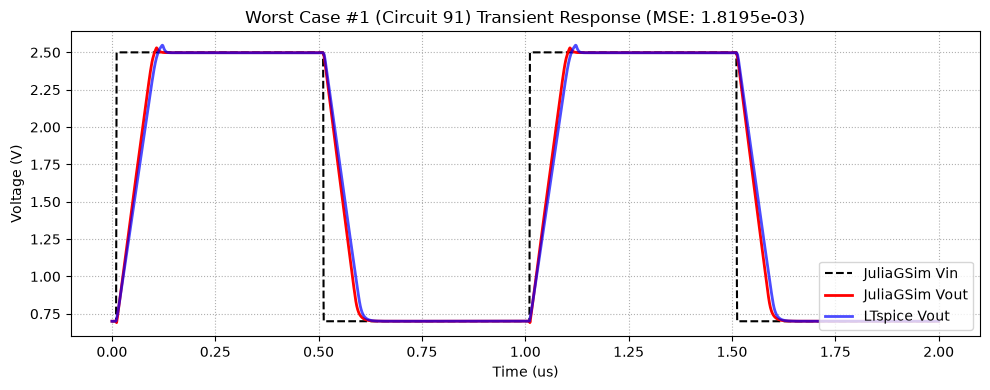


----------------------------------------------------------------------
Worst Case #2 (Circuit 92) - MSE: 1.7749e-03
Params: W=40.0um, L=2.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 21.18       V/us | 19.01       V/us
Difference      | 2.17        V/us |



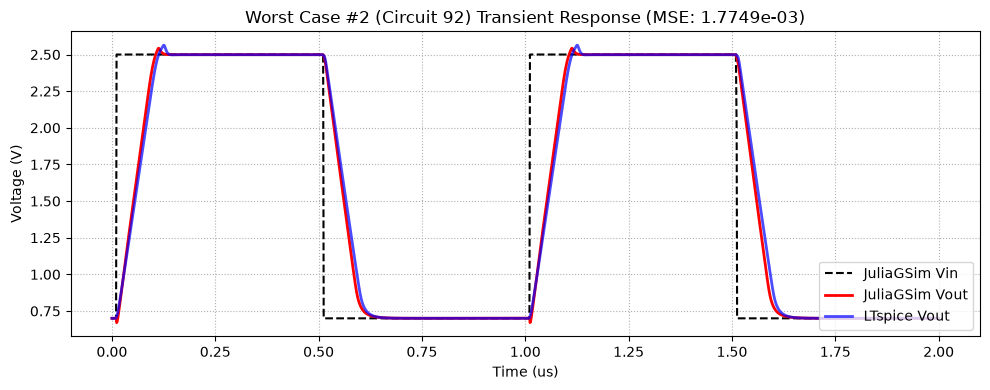


----------------------------------------------------------------------
Worst Case #3 (Circuit 71) - MSE: 1.7270e-03
Params: W=35.6um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 21.65       V/us | 19.42       V/us
Difference      | 2.23        V/us |



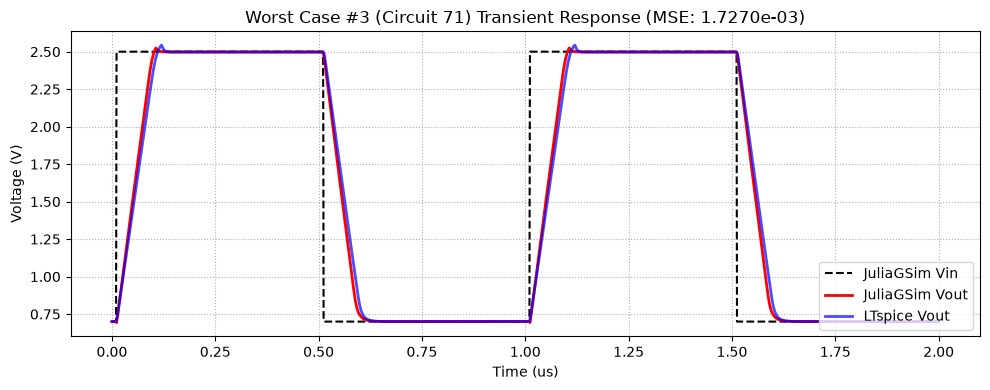


----------------------------------------------------------------------
Worst Case #4 (Circuit 81) - MSE: 1.7150e-03
Params: W=37.8um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 20.48       V/us | 19.31       V/us
Difference      | 1.17        V/us |



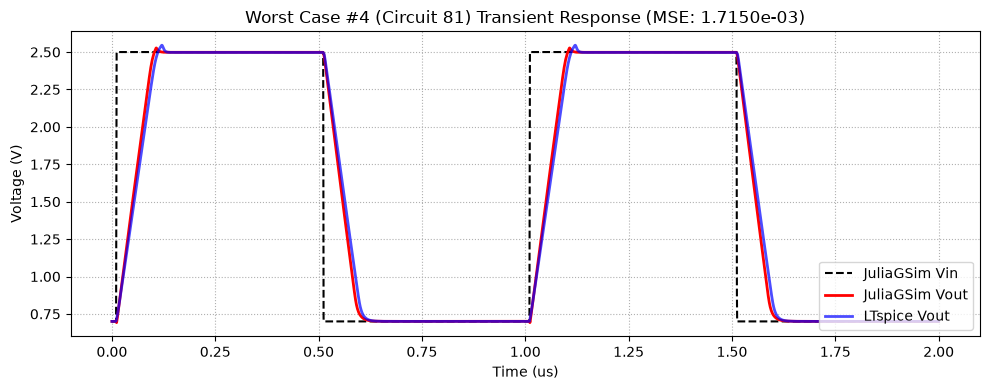


----------------------------------------------------------------------
Worst Case #5 (Circuit 61) - MSE: 1.5863e-03
Params: W=33.3um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 22.21       V/us | 19.53       V/us
Difference      | 2.68        V/us |



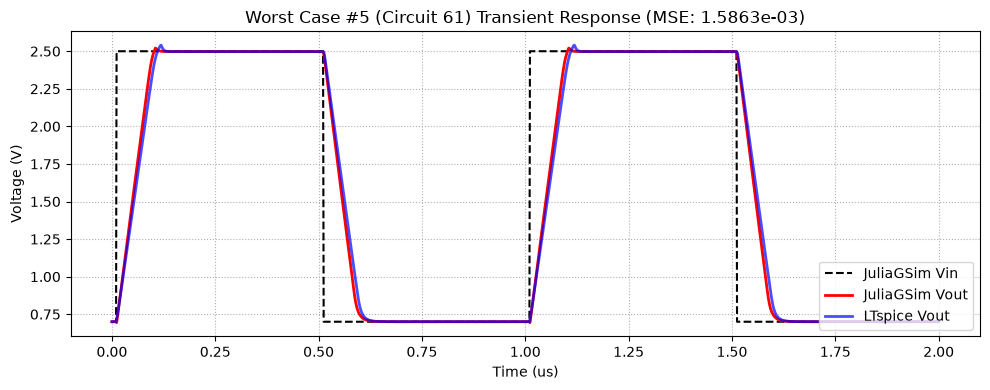


----------------------------------------------------------------------
Worst Case #6 (Circuit 82) - MSE: 1.5397e-03
Params: W=37.8um, L=2.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 21.94       V/us | 19.19       V/us
Difference      | 2.75        V/us |



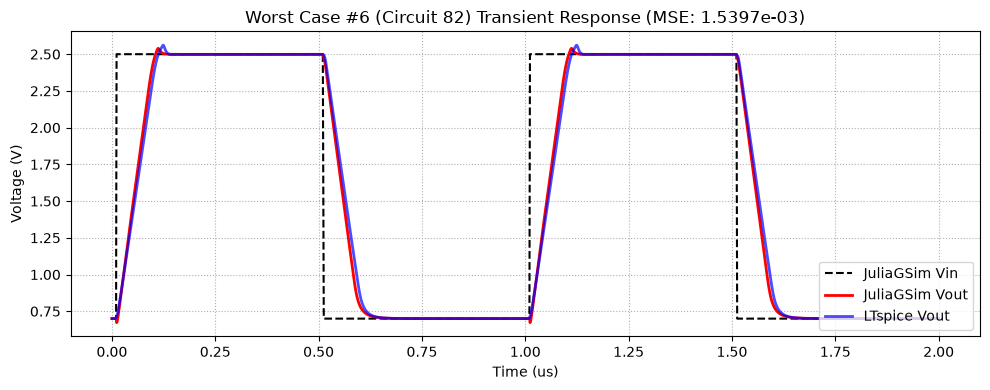


----------------------------------------------------------------------
Worst Case #7 (Circuit 51) - MSE: 1.3460e-03
Params: W=31.1um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 21.89       V/us | 19.64       V/us
Difference      | 2.25        V/us |



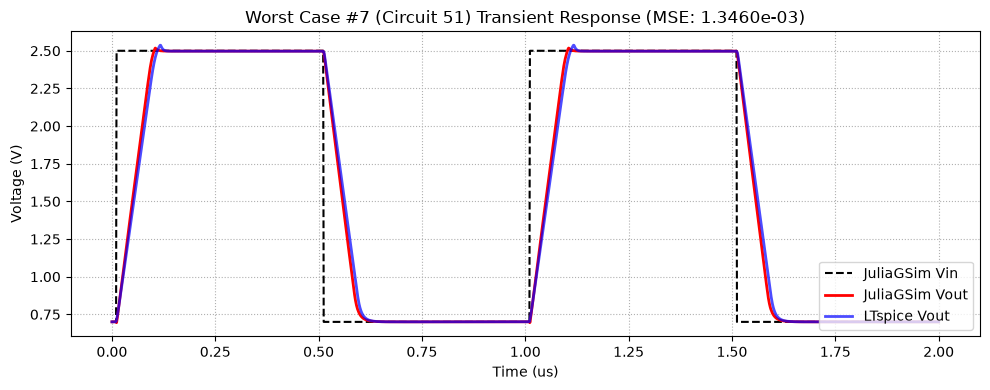


----------------------------------------------------------------------
Worst Case #8 (Circuit 93) - MSE: 1.2764e-03
Params: W=40.0um, L=3.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 20.65       V/us | 18.64       V/us
Difference      | 2.01        V/us |



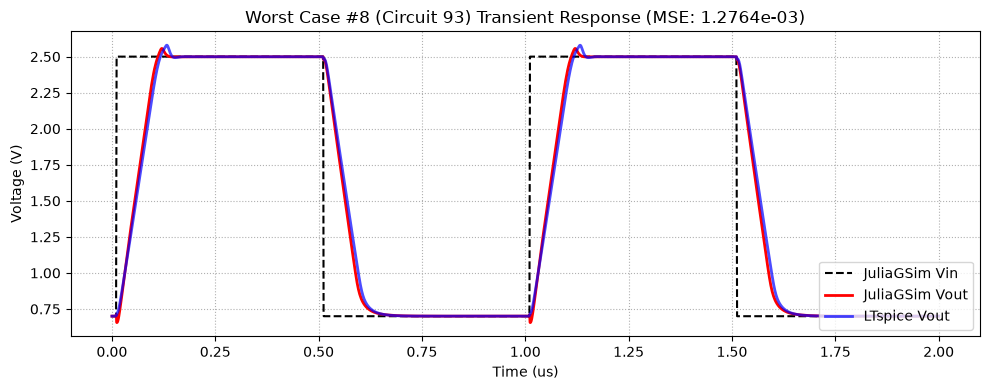


----------------------------------------------------------------------
Worst Case #9 (Circuit 72) - MSE: 1.2749e-03
Params: W=35.6um, L=2.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 22.76       V/us | 19.38       V/us
Difference      | 3.38        V/us |



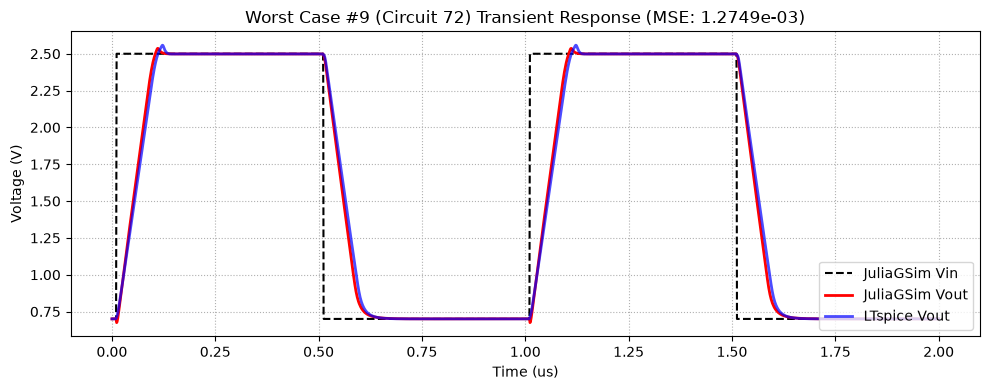


----------------------------------------------------------------------
Worst Case #10 (Circuit 83) - MSE: 1.1541e-03
Params: W=37.8um, L=3.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 21.84       V/us | 18.87       V/us
Difference      | 2.97        V/us |



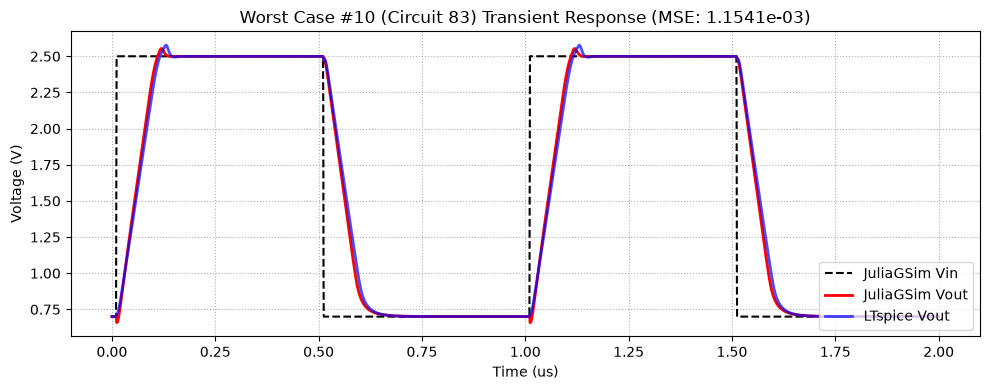

In [2]:
# 0. Set Python Environment
ENV["JULIA_PYTHONCALL_EXE"] = "C:\\Users\\mohamed\\.conda\\envs\\Thesis_Optimizer_Sandbox_Copy\\python.exe"

using Printf
using StaticArrays
using PythonCall
using Random
using JLD2
using Interpolations
using Statistics
using Base.Threads

# ==============================================================================
# 1. Call the Surrogate definitions and the simulator Engine
# ==============================================================================
# 1. Load technology model definitions
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Surrogate_definitions.jl")

# 2. Load the Engine (choose Static for small circuits or Sparse for large circuits)
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Static_Sim.jl")


# ==============================================================================
# 2. LTSPICE VERIFICATION GROUND TRUTH 
# ==============================================================================
g = pydict()
pyexec(raw"""
import os, subprocess, numpy as np
from PyLTSpice import RawRead

def run_ltspice_fc_tran(md, Ld, mp_src, Lp, mss, Lss, mp_csc, mm_mir, mm_csc, Lm, mb, Ib, I_cascode, CL, BASE_DIR='.'):
    os.makedirs(BASE_DIR, exist_ok=True)
    LTSPICE_PATH = r"C:\Users\Mohamed\AppData\Local\Programs\ADI\LTspice\LTspice.exe"
    
    m_bias_p_csc = mp_csc / 4.0
    m_bias_n_csc = mm_csc / 4.0
    I_tail = Ib * (mss/mb)
    I_pmos = I_tail/2.0 + I_cascode
    
    netlist = f'''* NMOS-Input Folded Cascode OTA Slew Rate Buffer Testbench
Vdd Vdd 0 3
Vin vip 0 PULSE(0.7 2.5 10n 1n 1n 500n 1u)
IB Vdd vb {Ib}

I_Vbp Vbp 0 {I_pmos}
I_VcscP VcscP 0 {I_cascode}
I_VcscN Vdd VcscN {I_cascode}

M_bias vb vb 0 0 nmos_3p3 l={Lss} w=0.5u m={mb}
M_bias_p Vbp Vbp Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={mp_src}
M_bias_cscP VcscP VcscP Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={m_bias_p_csc}
M_bias_cscN VcscN VcscN 0 0 nmos_3p3 l={Lm} w=0.5u m={m_bias_n_csc}

M_tail vT vb 0 0 nmos_3p3 l={Lss} w=0.5u m={mss}
M1 vfold_p vip vT 0 nmos_3p3 l={Ld} w=0.5u m={md}
M2 vfold_n vout vT 0 nmos_3p3 l={Ld} w=0.5u m={md}

M3 vfold_p Vbp Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={mp_src}
M4 vfold_n Vbp Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={mp_src}

M5 vx_left VcscP vfold_p Vdd pmos_3p3 l={Lp} w=0.5u m={mp_csc}
M6 vout VcscP vfold_n Vdd pmos_3p3 l={Lp} w=0.5u m={mp_csc}

M7 vy_left vx_left 0 0 nmos_3p3 l={Lm} w=0.5u m={mm_mir}
M8 vout_bot vx_left 0 0 nmos_3p3 l={Lm} w=0.5u m={mm_mir}

M9 vx_left VcscN vy_left 0 nmos_3p3 l={Lm} w=0.5u m={mm_csc}
M10 vout VcscN vout_bot 0 nmos_3p3 l={Lm} w=0.5u m={mm_csc}

CL vout 0 {CL}

.model NMOS NMOS
.model PMOS PMOS
.inc cmos_tt.txt
.lib {os.path.join(os.environ.get('LOCALAPPDATA', ''), 'LTspice', 'lib', 'cmp', 'standard.mos')}

.options plotwinsize=0
.tran 0 2u 0 1n
* MEASUREMENTS
.meas TRAN v_high FIND V(vout) AT 490n
.meas TRAN v_low FIND V(vout) AT 990n
.meas TRAN v_20 PARAM v_low + 0.2*(v_high-v_low)
.meas TRAN v_80 PARAM v_low + 0.8*(v_high-v_low)
.meas TRAN t_r20 FIND time WHEN V(vout)=v_20 RISE=1
.meas TRAN t_r80 FIND time WHEN V(vout)=v_80 RISE=1
.meas TRAN sr_rise PARAM (v_80-v_20)/(t_r80-t_r20)
.meas TRAN t_f80 FIND time WHEN V(vout)=v_80 FALL=1
.meas TRAN t_f20 FIND time WHEN V(vout)=v_20 FALL=1
.meas TRAN sr_fall PARAM (v_80-v_20)/(t_f20-t_f80)
.meas TRAN sr_avg PARAM (abs(sr_rise)+abs(sr_fall))/2
.end
'''
    sp_path = os.path.join(BASE_DIR, "tran_test_fc.sp")
    raw_path = os.path.join(BASE_DIR, "tran_test_fc.raw")
    log_path = os.path.join(BASE_DIR, "tran_test_fc.log")
    
    # Always ensure no stale raw data exists
    if os.path.exists(raw_path):
        os.remove(raw_path)
        
    with open(sp_path, 'w', encoding='utf-8') as f: f.write(netlist)
    subprocess.run([LTSPICE_PATH, "-b", "-run", sp_path], cwd=BASE_DIR, capture_output=True)
    raw = RawRead(raw_path)
    t = raw.get_trace("time").get_wave(0)
    vout = raw.get_trace("V(vout)").get_wave(0)
    vip = raw.get_trace("V(vip)").get_wave(0)
    
    sr = 0.0
    if os.path.exists(log_path):
        with open(log_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip().startswith('sr_avg:'):
                    try: sr = float(line.split('=')[1].strip())
                    except: pass
    return t, vip, vout, sr
""", g)
run_ltspice_fc_tran = g["run_ltspice_fc_tran"]

# ==============================================================================
# 3. CIRCUIT DEFINITIONS & 300-BATCH SETUP
# ==============================================================================
struct CircuitParams
    md::Float64; mp_src::Float64; mss::Float64; mp_csc::Float64
    mm_mir::Float64; mm_csc::Float64; mb::Float64
    m_bias_p_csc::Float64; m_bias_n_csc::Float64
    Ld::Float64; Lm::Float64; Lss::Float64; Lp::Float64
    I_pmos_val::Float64
end

VDD = 3.0
I_cascode = 20e-6
Ib = 20e-6
CL = 1e-12

W_arr = range(20e-6, stop=40e-6, length=10)
L_arr = range(1e-6, stop=10e-6, length=10)
W_flat = Float64[]
L_flat = Float64[]
for w in W_arr, l in L_arr
    push!(W_flat, w)
    push!(L_flat, l)
end
N_batch = length(W_flat) # 300 circuits

println("\n>>> Generating $(N_batch) circuit configurations...")

M_unit = 0.5e-6
md_np = W_flat ./ M_unit
mp_src_np = W_flat ./ M_unit
mss_np = W_flat ./ M_unit
mp_csc_np = (2.5 .* W_flat) ./ M_unit
mm_mir_np = (0.5 .* W_flat) ./ M_unit
mm_csc_np = (0.5 .* W_flat) ./ M_unit
mb_np = (0.5 .* W_flat) ./ M_unit

Ld_np = L_flat
Lm_np = L_flat
Lss_np = L_flat
Lp_np = 0.5 .* L_flat

m_bias_p_csc_np = mp_csc_np ./ 4.0
m_bias_n_csc_np = mm_csc_np ./ 4.0

circuits = Vector{CircuitParams}(undef, N_batch)
for i in 1:N_batch
    I_tail_val = Ib * (mss_np[i]/mb_np[i])
    I_pmos_val = I_tail_val / 2.0 + I_cascode
    
    circuits[i] = CircuitParams(
        md_np[i], mp_src_np[i], mss_np[i], mp_csc_np[i], 
        mm_mir_np[i], mm_csc_np[i], mb_np[i], 
        m_bias_p_csc_np[i], m_bias_n_csc_np[i], 
        Ld_np[i], Lm_np[i], Lss_np[i], Lp_np[i], I_pmos_val
    )
end

println("\n====================================================================")
println(" TRANSIENT BATCH EVALUATION: $(N_batch) CIRCUITS (FOLDED CASCODE BUFFER)")
println("====================================================================")

sim_tran = JuliaGSim(surrogate_model)
add_vsource!(sim_tran, "V_VDD", "VDD", "0", VDD)

pulse_fn = make_pulse(0.7, 2.5, 10e-9, 1e-9, 1e-9, 500e-9, 1e-6)
add_vsource!(sim_tran, "V_VIP", "vip", "0", pulse_fn)

add_isource!(sim_tran, "IB", "VDD", "vb", Ib)
add_isource!(sim_tran, "I_Vbp", "Vbp", "0", :I_pmos_val)
add_isource!(sim_tran, "I_VcscP", "VcscP", "0", I_cascode)
add_isource!(sim_tran, "I_VcscN", "VDD", "VcscN", I_cascode)

add_nmos!(sim_tran, "M_bias", d="vb", g="vb", s="0", b="0", M=:mb, L=:Lss)
add_pmos!(sim_tran, "M_bias_p", d="Vbp", g="Vbp", s="VDD", b="VDD", M=:mp_src, L=:Lp)
add_pmos!(sim_tran, "M_bias_cscP", d="VcscP", g="VcscP", s="VDD", b="VDD", M=:m_bias_p_csc, L=:Lp)
add_nmos!(sim_tran, "M_bias_cscN", d="VcscN", g="VcscN", s="0", b="0", M=:m_bias_n_csc, L=:Lm)

add_nmos!(sim_tran, "M_tail", d="vT", g="vb", s="0", b="0", M=:mss, L=:Lss)
add_nmos!(sim_tran, "M1", d="vfold_p", g="vip", s="vT", b="0", M=:md, L=:Ld)
add_nmos!(sim_tran, "M2", d="vfold_n", g="vout", s="vT", b="0", M=:md, L=:Ld)

add_pmos!(sim_tran, "M3", d="vfold_p", g="Vbp", s="VDD", b="VDD", M=:mp_src, L=:Lp)
add_pmos!(sim_tran, "M4", d="vfold_n", g="Vbp", s="VDD", b="VDD", M=:mp_src, L=:Lp)
add_pmos!(sim_tran, "M5", d="vx_left", g="VcscP", s="vfold_p", b="VDD", M=:mp_csc, L=:Lp)
add_pmos!(sim_tran, "M6", d="vout", g="VcscP", s="vfold_n", b="VDD", M=:mp_csc, L=:Lp)

add_nmos!(sim_tran, "M7", d="vy_left", g="vx_left", s="0", b="0", M=:mm_mir, L=:Lm)
add_nmos!(sim_tran, "M8", d="vout_bot", g="vx_left", s="0", b="0", M=:mm_mir, L=:Lm)
add_nmos!(sim_tran, "M9", d="vx_left", g="VcscN", s="vy_left", b="0", M=:mm_csc, L=:Lm)
add_nmos!(sim_tran, "M10", d="vout", g="VcscN", s="vout_bot", b="0", M=:mm_csc, L=:Lm)

add_cap!(sim_tran, "CL", "vout", "0", CL)
compile!(sim_tran)

BASE_DIR = pwd()

# ==============================================================================
# 4. RUN JULIAGSIM (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running $(N_batch)-Batch Transient Solves on $(nthreads()) Julia Threads...")

t_stop, dt = 2e-6, 0.1e-9
results_t_hist = Vector{Vector{Float64}}(undef, N_batch)
results_x_hist = Vector{Matrix{Float64}}(undef, N_batch)

start_time = time()
@threads for i in 1:N_batch
    t_hist_i, x_hist_i = solve_tran(sim_tran, circuits[i], t_stop, dt)
    results_t_hist[i] = t_hist_i
    results_x_hist[i] = x_hist_i
end
total_time = time() - start_time

println("Julia $(N_batch)-Circuit Transient Total Time: $(round(total_time, digits=4)) s")

# Save/overwrite fresh Julia simulation results to disk
julia_cache_file = joinpath(BASE_DIR, "julia_sim_cache_$(N_batch).jld2")
@save julia_cache_file results_t_hist results_x_hist total_time
println("    Saved fresh Julia results to: $julia_cache_file")

idx_vout = findfirst(==("vout"), sim_tran.unknown_nodes)

# ==============================================================================
# 5. RUN LTSPICE BASELINE (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running LTspice baseline (Sequential)...")

spice_times = Vector{Any}(undef, N_batch)
spice_vouts = Vector{Any}(undef, N_batch)
spice_vips  = Vector{Any}(undef, N_batch)
spice_srs   = zeros(N_batch)

start_spice = time()
for i in 1:N_batch
    t_lt, vip_lt, vout_lt, sr_lt = run_ltspice_fc_tran(
        circuits[i].md, circuits[i].Ld, circuits[i].mp_src, circuits[i].Lp,
        circuits[i].mss, circuits[i].Lss, circuits[i].mp_csc, circuits[i].mm_mir,
        circuits[i].mm_csc, circuits[i].Lm, circuits[i].mb, Ib, I_cascode, CL, BASE_DIR
    )
    spice_times[i] = pyconvert(Array, t_lt)
    spice_vouts[i] = pyconvert(Array, vout_lt)
    spice_vips[i]  = pyconvert(Array, vip_lt)
    spice_srs[i]   = pyconvert(Float64, sr_lt)
    if i % 30 == 0; println("    LTspice progress: $i/$N_batch circuits done..."); end
end
spice_time = time() - start_spice

println("LTspice Total Time: $(round(spice_time, digits=4)) s")

# Save/overwrite fresh LTspice simulation results to disk
spice_cache_file = joinpath(BASE_DIR, "ltspice_julia_cache_$(N_batch).jld2")
@save spice_cache_file spice_times spice_vouts spice_vips spice_srs spice_time
println("    Saved fresh LTspice results to: $spice_cache_file")

speedup = spice_time / total_time
println("\n======================================================================")
println(" 🚀 TRANSIENT PERFORMANCE SUMMARY")
println("======================================================================")
@printf(" JuliaGSim Time : %.3f seconds\n", total_time)
@printf(" LTspice Time   : %.3f seconds\n", spice_time)
@printf(" Speedup Factor : %.2fx faster than LTspice!\n", speedup)
println("======================================================================\n")

# ==============================================================================
# 6. MSE CALCULATION & 10 WORST-CASE WAVEFORM PLOTTING
# ==============================================================================
println(">>> Calculating MSE for all $(N_batch) circuits...")
errors = Tuple{Float64, Int}[]
for i in 1:N_batch
    t_jl = results_t_hist[i]
    vout_jl = results_x_hist[i][idx_vout, :]
    t_lt = spice_times[i]
    v_lt = spice_vouts[i]
    
    interp_linear = linear_interpolation(t_jl, vout_jl, extrapolation_bc=Line())
    v_jl_interp = interp_linear.(t_lt)
    
    mse = mean((v_jl_interp .- v_lt).^2)
    push!(errors, (mse, i))
end
sort!(errors, by = x -> x[1], rev=true)
worst_10 = errors[1:min(10, length(errors))]

plt = pyimport("matplotlib.pyplot")
println("======================================================================")
println(" DETAILED RESULTS FOR 10 WORST-CASE CIRCUITS (HIGHEST MSE)")
println("======================================================================\n")

for (idx, (mse, i)) in enumerate(worst_10)
    t_jl = results_t_hist[i]
    vout_jl = results_x_hist[i][idx_vout, :]
    vip_jl = [pulse_fn(t) for t in t_jl]
    
    idx_490 = findfirst(>=(490e-9), t_jl)
    idx_990 = findfirst(>=(990e-9), t_jl)
    v_high = idx_490 !== nothing ? vout_jl[idx_490] : vout_jl[end]
    v_low = idx_990 !== nothing ? vout_jl[idx_990] : vout_jl[1]
    v_20 = v_low + 0.2 * (v_high - v_low)
    v_80 = v_low + 0.8 * (v_high - v_low)

    idx_rise = findall(t_jl .< 500e-9)
    t_rise = t_jl[idx_rise]
    v_rise = vout_jl[idx_rise]
    ir20 = findfirst(>=(v_20), v_rise)
    ir80 = findfirst(>=(v_80), v_rise)
    t_r20 = (ir20 !== nothing) ? t_rise[ir20] : 0.0
    t_r80 = (ir80 !== nothing) ? t_rise[ir80] : 0.0
    sr_rise = (ir20 !== nothing && ir80 !== nothing && t_r80 > t_r20) ? (v_80 - v_20) / (t_r80 - t_r20) : 0.0

    idx_fall = findall(t_jl .>= 500e-9)
    t_fall = t_jl[idx_fall]
    v_fall = vout_jl[idx_fall]
    if80 = findfirst(<=(v_80), v_fall)
    if20 = findfirst(<=(v_20), v_fall)
    t_f80 = (if80 !== nothing) ? t_fall[if80] : 0.0
    t_f20 = (if20 !== nothing) ? t_fall[if20] : 0.0
    sr_fall = (if80 !== nothing && if20 !== nothing && t_f20 > t_f80) ? abs((v_80 - v_20) / (t_f20 - t_f80)) : 0.0

    sr_avg_jl = (sr_rise + sr_fall) / 2.0

    println(repeat("-", 70))
    println("Worst Case #$(idx) (Circuit $i) - MSE: $(@sprintf("%.4e", mse))")
    println("Params: W=$(round(W_flat[i]*1e6, digits=1))um, L=$(round(L_flat[i]*1e6, digits=1))um")
    println(repeat("-", 70))
    
    @printf("%-15s | %-15s | %-15s\n", "Metric", "JuliaGSim", "LTspice")
    println(repeat("-", 50))
    @printf("%-15s | %-11.2f V/us | %-11.2f V/us\n", "Slew Rate", sr_avg_jl / 1e6, spice_srs[i] / 1e6)
    @printf("%-15s | %-11.2f V/us |\n", "Difference", abs(sr_avg_jl - spice_srs[i]) / 1e6)
    println()

    fig = plt.figure(figsize=(10, 4))
    plt.plot(t_jl .* 1e6, vip_jl, "k--", label="JuliaGSim Vin")
    plt.plot(t_jl .* 1e6, vout_jl, "r-", linewidth=2, label="JuliaGSim Vout")
    plt.plot(spice_times[i] .* 1e6, spice_vouts[i], "b-", alpha=0.7, linewidth=2, label="LTspice Vout")
    
    plt.title("Worst Case #$(idx) (Circuit $i) Transient Response (MSE: $(@sprintf("%.4e", mse)))")
    plt.xlabel("Time (us)")
    plt.ylabel("Voltage (V)")
    plt.legend(loc="lower right")
    plt.grid(true, which="both", ls=":")
    plt.tight_layout()
    
    buf = pyimport("io").BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    png_data = pyconvert(Vector{UInt8}, buf.getvalue())
    display(MIME("image/png"), png_data)
    plt.close(fig) 
    println()
end


>>> Generating 300 circuit configurations...

 TRANSIENT BATCH EVALUATION: 300 CIRCUITS (FOLDED CASCODE BUFFER)
Compiled Custom DC, AC, and Transient Simulator Successfully!

>>> Running 300-Batch Transient Solves on 20 Julia Threads...
Julia 300-Circuit Transient Total Time: 3.452 s
    Saved fresh Julia results to: C:\Users\mohamed\Desktop\ML\CAD_projects\Netlists\GF_180nm_tech_work\project\New_Sim_tests\Allah_help_me2\Allah_Save_me\New folder\system\Testing\Spice_vs_Julia_Benchmarking\julia_sim_cache_300.jld2

>>> Running LTspice baseline (Sequential)...
    LTspice progress: 30/300 circuits done...
    LTspice progress: 60/300 circuits done...
    LTspice progress: 90/300 circuits done...
    LTspice progress: 120/300 circuits done...
    LTspice progress: 150/300 circuits done...
    LTspice progress: 180/300 circuits done...
    LTspice progress: 210/300 circuits done...
    LTspice progress: 240/300 circuits done...
    LTspice progress: 270/300 circuits done...
    LTspice pro

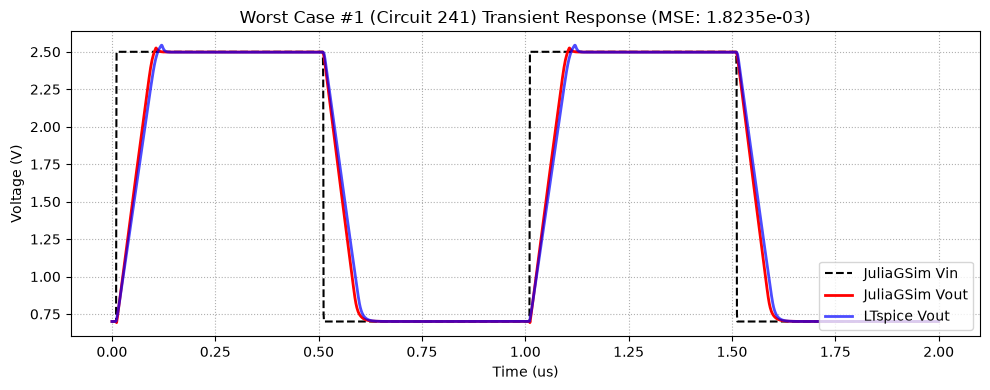


----------------------------------------------------------------------
Worst Case #2 (Circuit 291) - MSE: 1.8195e-03
Params: W=40.0um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 20.97       V/us | 19.20       V/us
Difference      | 1.77        V/us |



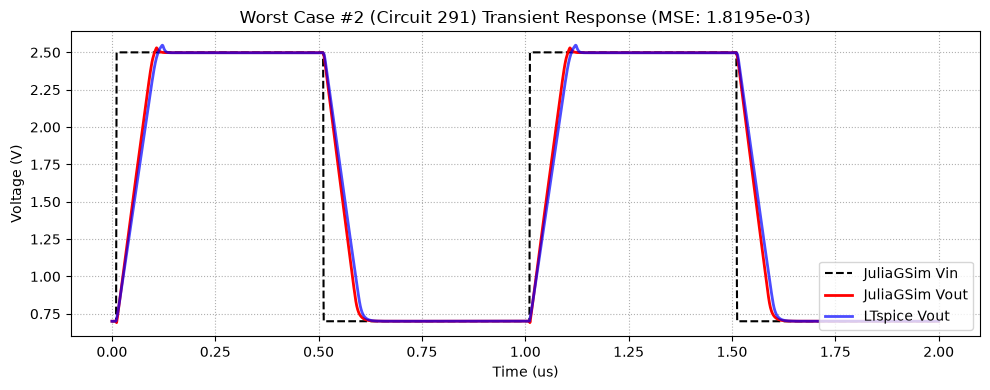


----------------------------------------------------------------------
Worst Case #3 (Circuit 271) - MSE: 1.7956e-03
Params: W=38.6um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 21.13       V/us | 19.27       V/us
Difference      | 1.86        V/us |



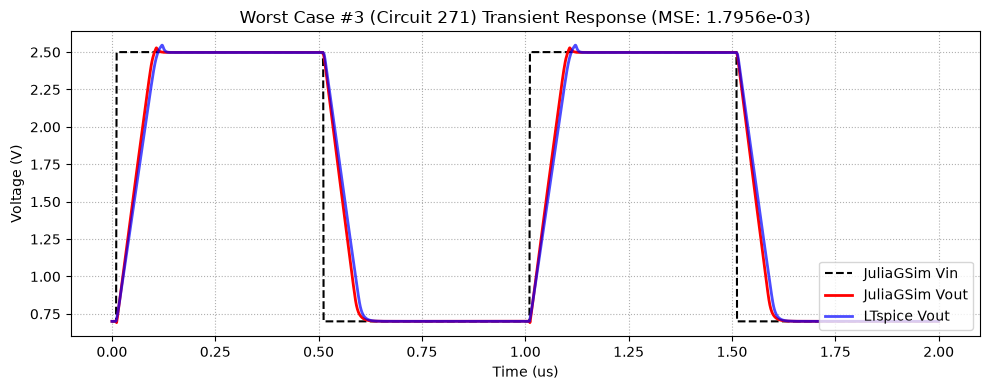


----------------------------------------------------------------------
Worst Case #4 (Circuit 292) - MSE: 1.7749e-03
Params: W=40.0um, L=2.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 21.18       V/us | 19.01       V/us
Difference      | 2.17        V/us |



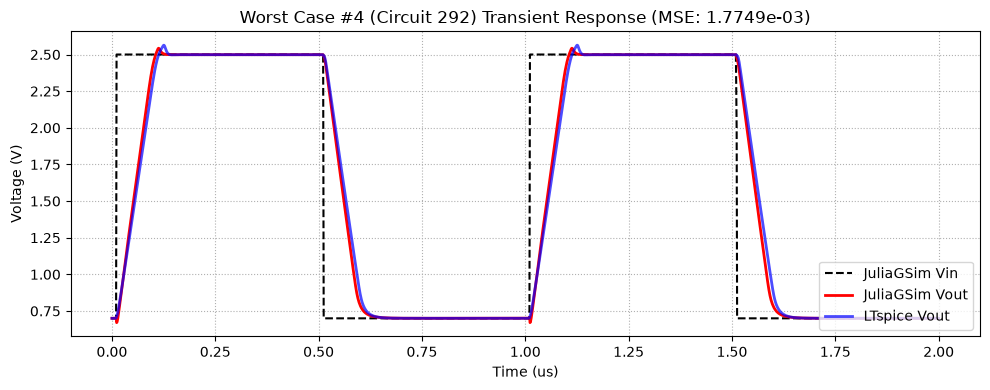


----------------------------------------------------------------------
Worst Case #5 (Circuit 281) - MSE: 1.7584e-03
Params: W=39.3um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 22.45       V/us | 19.23       V/us
Difference      | 3.22        V/us |



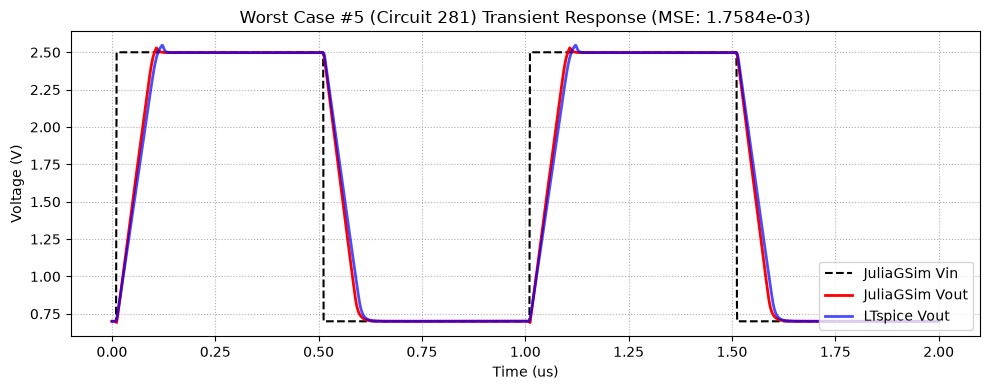


----------------------------------------------------------------------
Worst Case #6 (Circuit 211) - MSE: 1.7424e-03
Params: W=34.5um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 21.57       V/us | 19.47       V/us
Difference      | 2.09        V/us |



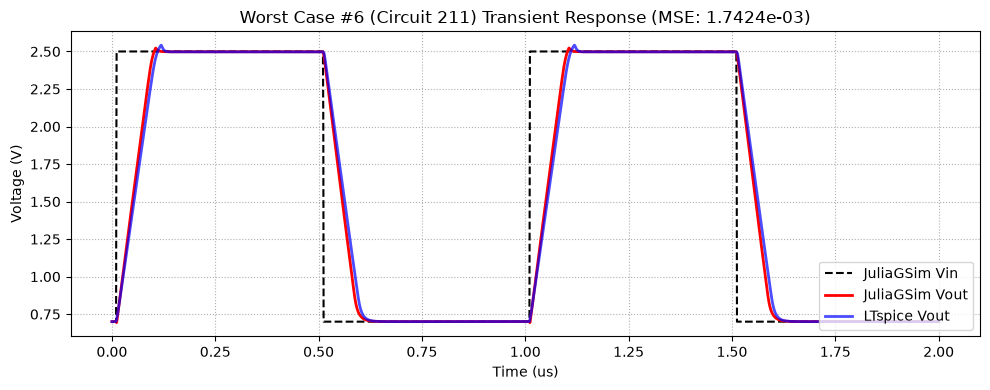


----------------------------------------------------------------------
Worst Case #7 (Circuit 262) - MSE: 1.7244e-03
Params: W=37.9um, L=2.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 22.36       V/us | 19.18       V/us
Difference      | 3.18        V/us |



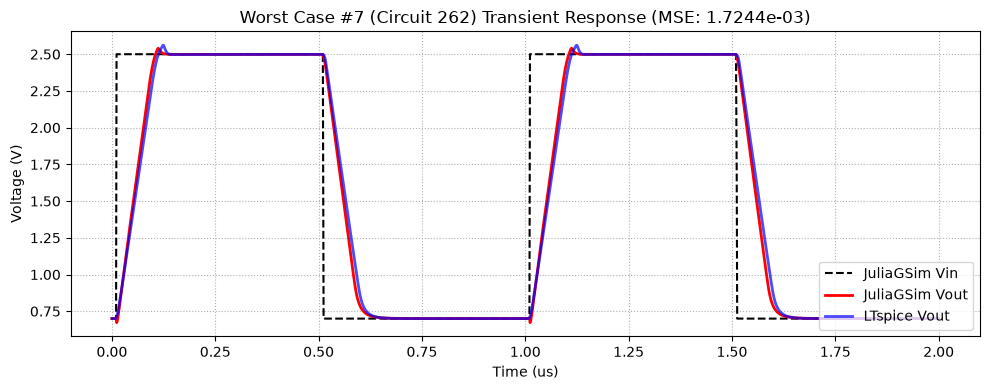


----------------------------------------------------------------------
Worst Case #8 (Circuit 221) - MSE: 1.7100e-03
Params: W=35.2um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 21.43       V/us | 19.44       V/us
Difference      | 1.99        V/us |



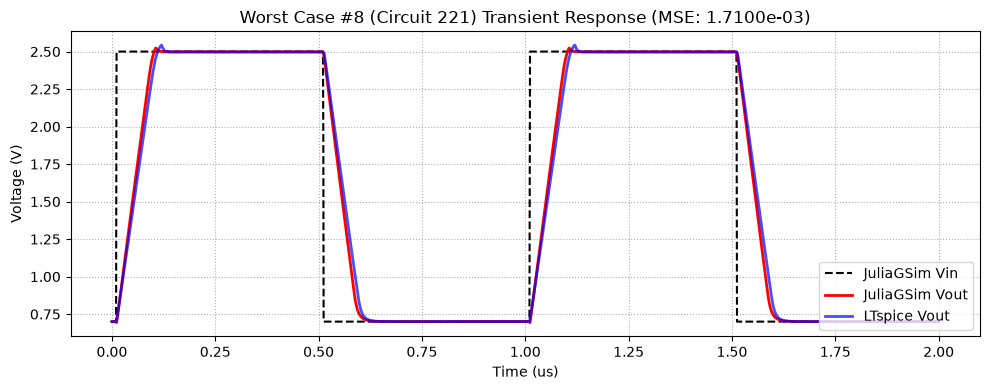


----------------------------------------------------------------------
Worst Case #9 (Circuit 231) - MSE: 1.7040e-03
Params: W=35.9um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 21.21       V/us | 19.40       V/us
Difference      | 1.80        V/us |



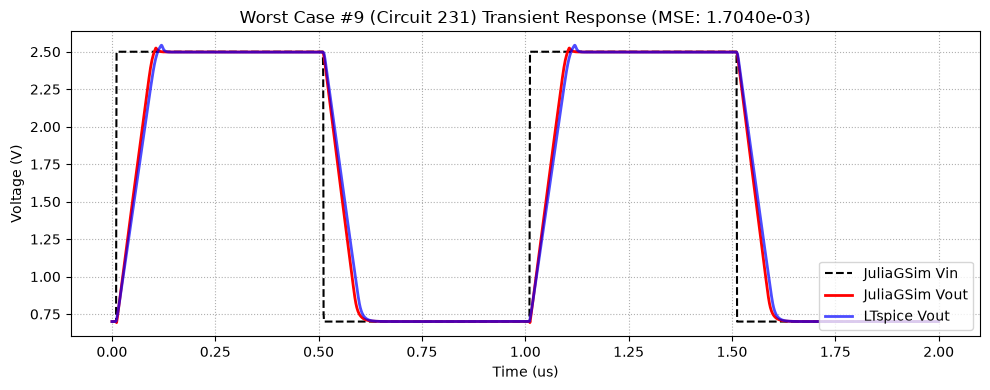


----------------------------------------------------------------------
Worst Case #10 (Circuit 251) - MSE: 1.6957e-03
Params: W=37.2um, L=1.0um
----------------------------------------------------------------------
Metric          | JuliaGSim       | LTspice        
--------------------------------------------------
Slew Rate       | 21.69       V/us | 19.34       V/us
Difference      | 2.36        V/us |



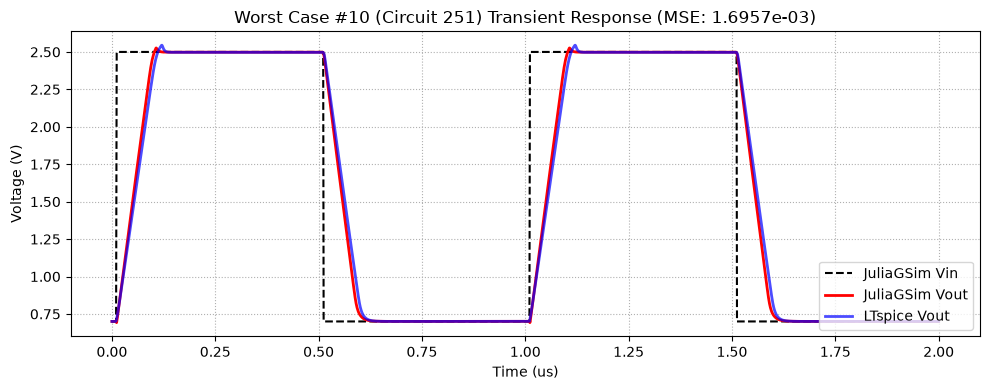

In [3]:
# 0. Set Python Environment
ENV["JULIA_PYTHONCALL_EXE"] = "C:\\Users\\mohamed\\.conda\\envs\\Thesis_Optimizer_Sandbox_Copy\\python.exe"

using Printf
using StaticArrays
using PythonCall
using Random
using JLD2
using Interpolations
using Statistics
using Base.Threads

# ==============================================================================
# 1. Call the Surrogate definitions and the simulator Engine
# ==============================================================================
# 1. Load technology model definitions
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Surrogate_definitions.jl")

# 2. Load the Engine (choose Static for small circuits or Sparse for large circuits)
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Static_Sim.jl")


# ==============================================================================
# 2. LTSPICE VERIFICATION GROUND TRUTH 
# ==============================================================================
g = pydict()
pyexec(raw"""
import os, subprocess, numpy as np
from PyLTSpice import RawRead

def run_ltspice_fc_tran(md, Ld, mp_src, Lp, mss, Lss, mp_csc, mm_mir, mm_csc, Lm, mb, Ib, I_cascode, CL, BASE_DIR='.'):
    os.makedirs(BASE_DIR, exist_ok=True)
    LTSPICE_PATH = r"C:\Users\Mohamed\AppData\Local\Programs\ADI\LTspice\LTspice.exe"
    
    m_bias_p_csc = mp_csc / 4.0
    m_bias_n_csc = mm_csc / 4.0
    I_tail = Ib * (mss/mb)
    I_pmos = I_tail/2.0 + I_cascode
    
    netlist = f'''* NMOS-Input Folded Cascode OTA Slew Rate Buffer Testbench
Vdd Vdd 0 3
Vin vip 0 PULSE(0.7 2.5 10n 1n 1n 500n 1u)
IB Vdd vb {Ib}

I_Vbp Vbp 0 {I_pmos}
I_VcscP VcscP 0 {I_cascode}
I_VcscN Vdd VcscN {I_cascode}

M_bias vb vb 0 0 nmos_3p3 l={Lss} w=0.5u m={mb}
M_bias_p Vbp Vbp Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={mp_src}
M_bias_cscP VcscP VcscP Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={m_bias_p_csc}
M_bias_cscN VcscN VcscN 0 0 nmos_3p3 l={Lm} w=0.5u m={m_bias_n_csc}

M_tail vT vb 0 0 nmos_3p3 l={Lss} w=0.5u m={mss}
M1 vfold_p vip vT 0 nmos_3p3 l={Ld} w=0.5u m={md}
M2 vfold_n vout vT 0 nmos_3p3 l={Ld} w=0.5u m={md}

M3 vfold_p Vbp Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={mp_src}
M4 vfold_n Vbp Vdd Vdd pmos_3p3 l={Lp} w=0.5u m={mp_src}

M5 vx_left VcscP vfold_p Vdd pmos_3p3 l={Lp} w=0.5u m={mp_csc}
M6 vout VcscP vfold_n Vdd pmos_3p3 l={Lp} w=0.5u m={mp_csc}

M7 vy_left vx_left 0 0 nmos_3p3 l={Lm} w=0.5u m={mm_mir}
M8 vout_bot vx_left 0 0 nmos_3p3 l={Lm} w=0.5u m={mm_mir}

M9 vx_left VcscN vy_left 0 nmos_3p3 l={Lm} w=0.5u m={mm_csc}
M10 vout VcscN vout_bot 0 nmos_3p3 l={Lm} w=0.5u m={mm_csc}

CL vout 0 {CL}

.model NMOS NMOS
.model PMOS PMOS
.inc cmos_tt.txt
.lib {os.path.join(os.environ.get('LOCALAPPDATA', ''), 'LTspice', 'lib', 'cmp', 'standard.mos')}

.options plotwinsize=0
.tran 0 2u 0 1n
* MEASUREMENTS
.meas TRAN v_high FIND V(vout) AT 490n
.meas TRAN v_low FIND V(vout) AT 990n
.meas TRAN v_20 PARAM v_low + 0.2*(v_high-v_low)
.meas TRAN v_80 PARAM v_low + 0.8*(v_high-v_low)
.meas TRAN t_r20 FIND time WHEN V(vout)=v_20 RISE=1
.meas TRAN t_r80 FIND time WHEN V(vout)=v_80 RISE=1
.meas TRAN sr_rise PARAM (v_80-v_20)/(t_r80-t_r20)
.meas TRAN t_f80 FIND time WHEN V(vout)=v_80 FALL=1
.meas TRAN t_f20 FIND time WHEN V(vout)=v_20 FALL=1
.meas TRAN sr_fall PARAM (v_80-v_20)/(t_f20-t_f80)
.meas TRAN sr_avg PARAM (abs(sr_rise)+abs(sr_fall))/2
.end
'''
    sp_path = os.path.join(BASE_DIR, "tran_test_fc.sp")
    raw_path = os.path.join(BASE_DIR, "tran_test_fc.raw")
    log_path = os.path.join(BASE_DIR, "tran_test_fc.log")
    
    # Always ensure no stale raw data exists
    if os.path.exists(raw_path):
        os.remove(raw_path)
        
    with open(sp_path, 'w', encoding='utf-8') as f: f.write(netlist)
    subprocess.run([LTSPICE_PATH, "-b", "-run", sp_path], cwd=BASE_DIR, capture_output=True)
    raw = RawRead(raw_path)
    t = raw.get_trace("time").get_wave(0)
    vout = raw.get_trace("V(vout)").get_wave(0)
    vip = raw.get_trace("V(vip)").get_wave(0)
    
    sr = 0.0
    if os.path.exists(log_path):
        with open(log_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip().startswith('sr_avg:'):
                    try: sr = float(line.split('=')[1].strip())
                    except: pass
    return t, vip, vout, sr
""", g)
run_ltspice_fc_tran = g["run_ltspice_fc_tran"]

# ==============================================================================
# 3. CIRCUIT DEFINITIONS & 300-BATCH SETUP
# ==============================================================================
struct CircuitParams
    md::Float64; mp_src::Float64; mss::Float64; mp_csc::Float64
    mm_mir::Float64; mm_csc::Float64; mb::Float64
    m_bias_p_csc::Float64; m_bias_n_csc::Float64
    Ld::Float64; Lm::Float64; Lss::Float64; Lp::Float64
    I_pmos_val::Float64
end

VDD = 3.0
I_cascode = 20e-6
Ib = 20e-6
CL = 1e-12

W_arr = range(20e-6, stop=40e-6, length=30)
L_arr = range(1e-6, stop=10e-6, length=10)
W_flat = Float64[]
L_flat = Float64[]
for w in W_arr, l in L_arr
    push!(W_flat, w)
    push!(L_flat, l)
end
N_batch = length(W_flat) # 300 circuits

println("\n>>> Generating $(N_batch) circuit configurations...")

M_unit = 0.5e-6
md_np = W_flat ./ M_unit
mp_src_np = W_flat ./ M_unit
mss_np = W_flat ./ M_unit
mp_csc_np = (2.5 .* W_flat) ./ M_unit
mm_mir_np = (0.5 .* W_flat) ./ M_unit
mm_csc_np = (0.5 .* W_flat) ./ M_unit
mb_np = (0.5 .* W_flat) ./ M_unit

Ld_np = L_flat
Lm_np = L_flat
Lss_np = L_flat
Lp_np = 0.5 .* L_flat

m_bias_p_csc_np = mp_csc_np ./ 4.0
m_bias_n_csc_np = mm_csc_np ./ 4.0

circuits = Vector{CircuitParams}(undef, N_batch)
for i in 1:N_batch
    I_tail_val = Ib * (mss_np[i]/mb_np[i])
    I_pmos_val = I_tail_val / 2.0 + I_cascode
    
    circuits[i] = CircuitParams(
        md_np[i], mp_src_np[i], mss_np[i], mp_csc_np[i], 
        mm_mir_np[i], mm_csc_np[i], mb_np[i], 
        m_bias_p_csc_np[i], m_bias_n_csc_np[i], 
        Ld_np[i], Lm_np[i], Lss_np[i], Lp_np[i], I_pmos_val
    )
end

println("\n====================================================================")
println(" TRANSIENT BATCH EVALUATION: $(N_batch) CIRCUITS (FOLDED CASCODE BUFFER)")
println("====================================================================")

sim_tran = JuliaGSim(surrogate_model)
add_vsource!(sim_tran, "V_VDD", "VDD", "0", VDD)

pulse_fn = make_pulse(0.7, 2.5, 10e-9, 1e-9, 1e-9, 500e-9, 1e-6)
add_vsource!(sim_tran, "V_VIP", "vip", "0", pulse_fn)

add_isource!(sim_tran, "IB", "VDD", "vb", Ib)
add_isource!(sim_tran, "I_Vbp", "Vbp", "0", :I_pmos_val)
add_isource!(sim_tran, "I_VcscP", "VcscP", "0", I_cascode)
add_isource!(sim_tran, "I_VcscN", "VDD", "VcscN", I_cascode)

add_nmos!(sim_tran, "M_bias", d="vb", g="vb", s="0", b="0", M=:mb, L=:Lss)
add_pmos!(sim_tran, "M_bias_p", d="Vbp", g="Vbp", s="VDD", b="VDD", M=:mp_src, L=:Lp)
add_pmos!(sim_tran, "M_bias_cscP", d="VcscP", g="VcscP", s="VDD", b="VDD", M=:m_bias_p_csc, L=:Lp)
add_nmos!(sim_tran, "M_bias_cscN", d="VcscN", g="VcscN", s="0", b="0", M=:m_bias_n_csc, L=:Lm)

add_nmos!(sim_tran, "M_tail", d="vT", g="vb", s="0", b="0", M=:mss, L=:Lss)
add_nmos!(sim_tran, "M1", d="vfold_p", g="vip", s="vT", b="0", M=:md, L=:Ld)
add_nmos!(sim_tran, "M2", d="vfold_n", g="vout", s="vT", b="0", M=:md, L=:Ld)

add_pmos!(sim_tran, "M3", d="vfold_p", g="Vbp", s="VDD", b="VDD", M=:mp_src, L=:Lp)
add_pmos!(sim_tran, "M4", d="vfold_n", g="Vbp", s="VDD", b="VDD", M=:mp_src, L=:Lp)
add_pmos!(sim_tran, "M5", d="vx_left", g="VcscP", s="vfold_p", b="VDD", M=:mp_csc, L=:Lp)
add_pmos!(sim_tran, "M6", d="vout", g="VcscP", s="vfold_n", b="VDD", M=:mp_csc, L=:Lp)

add_nmos!(sim_tran, "M7", d="vy_left", g="vx_left", s="0", b="0", M=:mm_mir, L=:Lm)
add_nmos!(sim_tran, "M8", d="vout_bot", g="vx_left", s="0", b="0", M=:mm_mir, L=:Lm)
add_nmos!(sim_tran, "M9", d="vx_left", g="VcscN", s="vy_left", b="0", M=:mm_csc, L=:Lm)
add_nmos!(sim_tran, "M10", d="vout", g="VcscN", s="vout_bot", b="0", M=:mm_csc, L=:Lm)

add_cap!(sim_tran, "CL", "vout", "0", CL)
compile!(sim_tran)

BASE_DIR = pwd()

# ==============================================================================
# 4. RUN JULIAGSIM (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running $(N_batch)-Batch Transient Solves on $(nthreads()) Julia Threads...")

t_stop, dt = 2e-6, 0.1e-9
results_t_hist = Vector{Vector{Float64}}(undef, N_batch)
results_x_hist = Vector{Matrix{Float64}}(undef, N_batch)

start_time = time()
@threads for i in 1:N_batch
    t_hist_i, x_hist_i = solve_tran(sim_tran, circuits[i], t_stop, dt)
    results_t_hist[i] = t_hist_i
    results_x_hist[i] = x_hist_i
end
total_time = time() - start_time

println("Julia $(N_batch)-Circuit Transient Total Time: $(round(total_time, digits=4)) s")

# Save/overwrite fresh Julia simulation results to disk
julia_cache_file = joinpath(BASE_DIR, "julia_sim_cache_$(N_batch).jld2")
@save julia_cache_file results_t_hist results_x_hist total_time
println("    Saved fresh Julia results to: $julia_cache_file")

idx_vout = findfirst(==("vout"), sim_tran.unknown_nodes)

# ==============================================================================
# 5. RUN LTSPICE BASELINE (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running LTspice baseline (Sequential)...")

spice_times = Vector{Any}(undef, N_batch)
spice_vouts = Vector{Any}(undef, N_batch)
spice_vips  = Vector{Any}(undef, N_batch)
spice_srs   = zeros(N_batch)

start_spice = time()
for i in 1:N_batch
    t_lt, vip_lt, vout_lt, sr_lt = run_ltspice_fc_tran(
        circuits[i].md, circuits[i].Ld, circuits[i].mp_src, circuits[i].Lp,
        circuits[i].mss, circuits[i].Lss, circuits[i].mp_csc, circuits[i].mm_mir,
        circuits[i].mm_csc, circuits[i].Lm, circuits[i].mb, Ib, I_cascode, CL, BASE_DIR
    )
    spice_times[i] = pyconvert(Array, t_lt)
    spice_vouts[i] = pyconvert(Array, vout_lt)
    spice_vips[i]  = pyconvert(Array, vip_lt)
    spice_srs[i]   = pyconvert(Float64, sr_lt)
    if i % 30 == 0; println("    LTspice progress: $i/$N_batch circuits done..."); end
end
spice_time = time() - start_spice

println("LTspice Total Time: $(round(spice_time, digits=4)) s")

# Save/overwrite fresh LTspice simulation results to disk
spice_cache_file = joinpath(BASE_DIR, "ltspice_julia_cache_$(N_batch).jld2")
@save spice_cache_file spice_times spice_vouts spice_vips spice_srs spice_time
println("    Saved fresh LTspice results to: $spice_cache_file")

speedup = spice_time / total_time
println("\n======================================================================")
println(" 🚀 TRANSIENT PERFORMANCE SUMMARY")
println("======================================================================")
@printf(" JuliaGSim Time : %.3f seconds\n", total_time)
@printf(" LTspice Time   : %.3f seconds\n", spice_time)
@printf(" Speedup Factor : %.2fx faster than LTspice!\n", speedup)
println("======================================================================\n")

# ==============================================================================
# 6. MSE CALCULATION & 10 WORST-CASE WAVEFORM PLOTTING
# ==============================================================================
println(">>> Calculating MSE for all $(N_batch) circuits...")
errors = Tuple{Float64, Int}[]
for i in 1:N_batch
    t_jl = results_t_hist[i]
    vout_jl = results_x_hist[i][idx_vout, :]
    t_lt = spice_times[i]
    v_lt = spice_vouts[i]
    
    interp_linear = linear_interpolation(t_jl, vout_jl, extrapolation_bc=Line())
    v_jl_interp = interp_linear.(t_lt)
    
    mse = mean((v_jl_interp .- v_lt).^2)
    push!(errors, (mse, i))
end
sort!(errors, by = x -> x[1], rev=true)
worst_10 = errors[1:min(10, length(errors))]

plt = pyimport("matplotlib.pyplot")
println("======================================================================")
println(" DETAILED RESULTS FOR 10 WORST-CASE CIRCUITS (HIGHEST MSE)")
println("======================================================================\n")

for (idx, (mse, i)) in enumerate(worst_10)
    t_jl = results_t_hist[i]
    vout_jl = results_x_hist[i][idx_vout, :]
    vip_jl = [pulse_fn(t) for t in t_jl]
    
    idx_490 = findfirst(>=(490e-9), t_jl)
    idx_990 = findfirst(>=(990e-9), t_jl)
    v_high = idx_490 !== nothing ? vout_jl[idx_490] : vout_jl[end]
    v_low = idx_990 !== nothing ? vout_jl[idx_990] : vout_jl[1]
    v_20 = v_low + 0.2 * (v_high - v_low)
    v_80 = v_low + 0.8 * (v_high - v_low)

    idx_rise = findall(t_jl .< 500e-9)
    t_rise = t_jl[idx_rise]
    v_rise = vout_jl[idx_rise]
    ir20 = findfirst(>=(v_20), v_rise)
    ir80 = findfirst(>=(v_80), v_rise)
    t_r20 = (ir20 !== nothing) ? t_rise[ir20] : 0.0
    t_r80 = (ir80 !== nothing) ? t_rise[ir80] : 0.0
    sr_rise = (ir20 !== nothing && ir80 !== nothing && t_r80 > t_r20) ? (v_80 - v_20) / (t_r80 - t_r20) : 0.0

    idx_fall = findall(t_jl .>= 500e-9)
    t_fall = t_jl[idx_fall]
    v_fall = vout_jl[idx_fall]
    if80 = findfirst(<=(v_80), v_fall)
    if20 = findfirst(<=(v_20), v_fall)
    t_f80 = (if80 !== nothing) ? t_fall[if80] : 0.0
    t_f20 = (if20 !== nothing) ? t_fall[if20] : 0.0
    sr_fall = (if80 !== nothing && if20 !== nothing && t_f20 > t_f80) ? abs((v_80 - v_20) / (t_f20 - t_f80)) : 0.0

    sr_avg_jl = (sr_rise + sr_fall) / 2.0

    println(repeat("-", 70))
    println("Worst Case #$(idx) (Circuit $i) - MSE: $(@sprintf("%.4e", mse))")
    println("Params: W=$(round(W_flat[i]*1e6, digits=1))um, L=$(round(L_flat[i]*1e6, digits=1))um")
    println(repeat("-", 70))
    
    @printf("%-15s | %-15s | %-15s\n", "Metric", "JuliaGSim", "LTspice")
    println(repeat("-", 50))
    @printf("%-15s | %-11.2f V/us | %-11.2f V/us\n", "Slew Rate", sr_avg_jl / 1e6, spice_srs[i] / 1e6)
    @printf("%-15s | %-11.2f V/us |\n", "Difference", abs(sr_avg_jl - spice_srs[i]) / 1e6)
    println()

    fig = plt.figure(figsize=(10, 4))
    plt.plot(t_jl .* 1e6, vip_jl, "k--", label="JuliaGSim Vin")
    plt.plot(t_jl .* 1e6, vout_jl, "r-", linewidth=2, label="JuliaGSim Vout")
    plt.plot(spice_times[i] .* 1e6, spice_vouts[i], "b-", alpha=0.7, linewidth=2, label="LTspice Vout")
    
    plt.title("Worst Case #$(idx) (Circuit $i) Transient Response (MSE: $(@sprintf("%.4e", mse)))")
    plt.xlabel("Time (us)")
    plt.ylabel("Voltage (V)")
    plt.legend(loc="lower right")
    plt.grid(true, which="both", ls=":")
    plt.tight_layout()
    
    buf = pyimport("io").BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    png_data = pyconvert(Vector{UInt8}, buf.getvalue())
    display(MIME("image/png"), png_data)
    plt.close(fig) 
    println()
end